# Prolog

In [1]:
import pandas as pd
import seaborn as sb
import os
import OHCParser as op
import datetime
import traceback
from scipy.optimize import curve_fit
import pathlib
import matplotlib.pyplot as plt

In [2]:
dfs = op.read_submissions() # OHC2 only
dfs = op.derive_metrics(dfs)

# Sort columns ans save the DataFrame to a JSON file with pretty printing
# dfs = dfs.reindex(sorted(dfs.columns), axis=1)
# dfs.to_json("data.json", orient="records", lines=False, indent=4)

last time the data was updated 2026-10-31 10:43:13.925346  by  go
01_Wikki_DrivAer_hardware_236M Sergey Lesnik (Wikki).xlsm: 3 of 11 runs without energy data


01_Wikki_DrivAer_hardware_65M Sergey Lesnik (Wikki).xlsm: 4 of 11 runs without energy data


NOTE: 'Energy per Iteration [J]', 'Energy per Iteration [kJ]' and 'Energy-To-Solution [kWh]' are TDP-based for all entries.


In [3]:
df_hardware = dfs[dfs["Track"] == "Hardware Track"]
df_software = dfs[dfs["Track"] == "Software Track"]

fig_folder = "figures_overview"
doSaveFig = False  # Set to True to save figures

In [4]:
# olympic swimming pool 50m*25m*2m 2.5e6 l water
V = 2.5e6 #l water
cp = 4.184  # kJ / kg⋅K
dT = 80 #K,
rho = 1 #kg/l
# 1kJ = 0.0002778 kWh
e = V * rho * dT * cp * 0.0002778

In [5]:
dfs.columns

Index(['Contributor Affiliation', 'File Name', 'Run Wall-Clock Time [s]',
       'Pre-Processing Wall-Clock Time [s]', 'Storage File-System',
       'Number of CPU Cores', 'Number of GPU Devices', 'Number of Nodes',
       'CPU Family', 'CPU Model', 'CPU Submodel', 'CPU Generation',
       'CPU Memory Bandwidth [GB/s]', 'GPU Model',
       'GPU Memory Bandwidth [GB/s]', 'Mesh', 'System TDP [W]',
       'Number of Cells', 'Time per Iteration [s]', 'Track', 'OpenFOAM Flavor',
       'Run Consumed Energy [kWh]', 'Decomposition Method', 'Last-Level Cache',
       'Network Interconnect', 'Renumbering Method', 'Contributor ID',
       'Is Partial', 'Is Energy Reported', 'Software Optimization Category',
       'Total Core Time [s]', 'Total Node Time [s]',
       'Energy per Iteration [J]', 'Energy per Iteration [kJ]',
       'Energy-To-Solution [kWh]', 'Time-To-Solution [h]',
       'Core-Time-To-Solution [h]', 'Node-Time-To-Solution [h]', 'FVOPS',
       'FVOPS per Energy', 'FVOPS per kW', 

# Results

In [6]:
# some statistics
print(f"""
total number of valid entries: {len(dfs)},
hardware track entries {len(df_hardware)},
software track entries {len(df_software)} ,
processesed {len(set(dfs['CPU Family']))} CPU families with {len(set(dfs['CPU Submodel']))} CPU Submodels,
-------------------
break-down by CPU Family: {df_hardware["CPU Family"].value_counts()}
-------------------
max nodes {max(dfs['Number of Nodes'])},
mmax cores {max(dfs['Number of CPU Cores'])},
min wall clc {min(dfs['Run Wall-Clock Time [s]'])},
min time step {min(dfs['Time per Iteration [s]'])},
min energy {min(dfs['Energy-To-Solution [kWh]'])} [kWh],
max energy {max(dfs['Energy-To-Solution [kWh]'])} [kWh],
total reported energy consumption {sum(dfs['Energy-To-Solution [kWh]'])} kWh, bringing {sum(dfs['Energy-To-Solution [kWh]'])/e} olympic swimming pools worth of water to a boil
decomposition methods {set(dfs["Decomposition Method"])},
renumbering methods {set(dfs["Renumbering Method"])}
network {set(dfs["Network Interconnect"])},
""")


total number of valid entries: 148,
hardware track entries 86,
software track entries 62 ,
processesed 4 CPU families with 14 CPU Submodels,
-------------------
break-down by CPU Family: CPU Family
AMD        73
Fujitsu     7
NVIDIA      6
Name: count, dtype: int64
-------------------
max nodes 512,
mmax cores 65536,
min wall clc 330.0,
min time step 0.0751141500755188,
min energy 0.7536666666666666 [kWh],
max energy 103.92649999999999 [kWh],
total reported energy consumption 2366.059656770684 kWh, bringing 0.010178218682723431 olympic swimming pools worth of water to a boil
decomposition methods {'Scotch', 'hierarchical', 'hierarchical [default]', 'ס', 'multiLevel (scotch)', 'multiLevel scotch', 'Hierarchical (16 4 2)', 'scotch', 'Hierarchical (6 6 4)', 'N/A', 'Hierarchical', 'standard'},
renumbering methods {'CuthillMcKee', 'standard', 'CuthillMcKee [default]', 'RCM'}
network {'NVLink', 'IB EDR 100Gb/s', '200 Gbps NVIDIA Mellanox HDR InfiniBand', 'NDR Infinibad (200 Gbit)', 'NVIDIA 

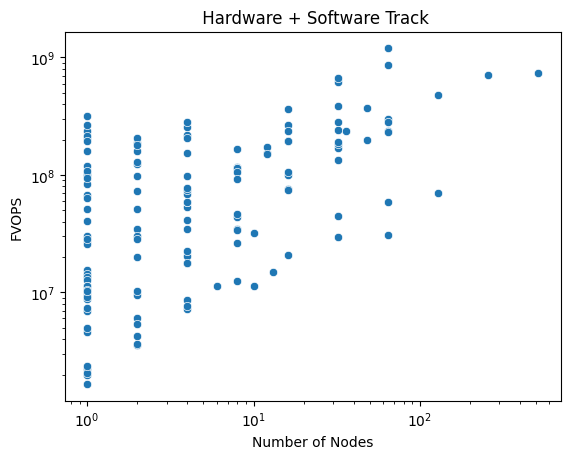

In [7]:
fig, ax = plt.subplots()
sb.scatterplot(dfs, x="Number of Nodes", y="FVOPS", ax=ax)#, hue="Track")
ax.set(xscale="log", yscale="log", title=" Hardware + Software Track")
#sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "FVOPSAllsubs", doSaveFig)

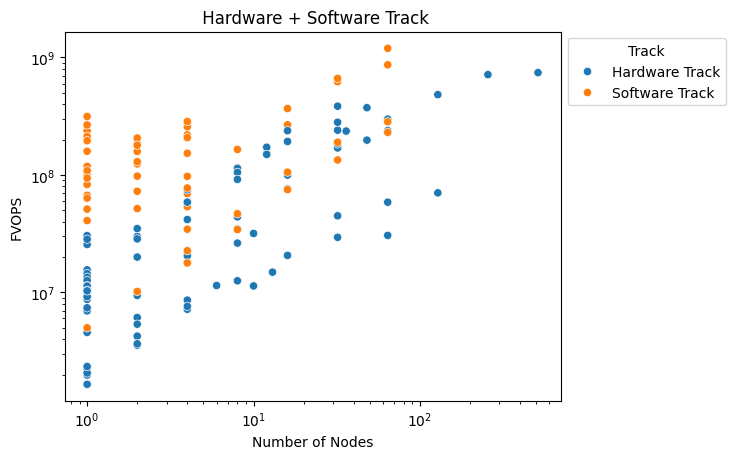

In [8]:
fig, ax = plt.subplots()
sb.scatterplot(dfs, x="Number of Nodes", y="FVOPS", hue="Track", ax=ax)
ax.set(xscale="log", yscale="log", title=" Hardware + Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "FVOPSAllsubsByTrack", doSaveFig)

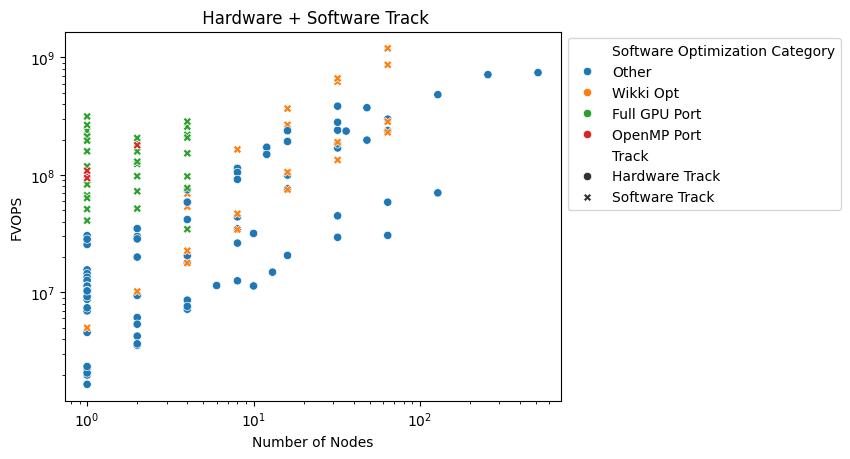

In [9]:
fig, ax = plt.subplots()
sb.scatterplot(dfs, x="Number of Nodes", y="FVOPS", hue="Software Optimization Category", style="Track", ax=ax)
ax.set(xscale="log", yscale="log", title=" Hardware + Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "FVOPSAllsubsByType", doSaveFig)

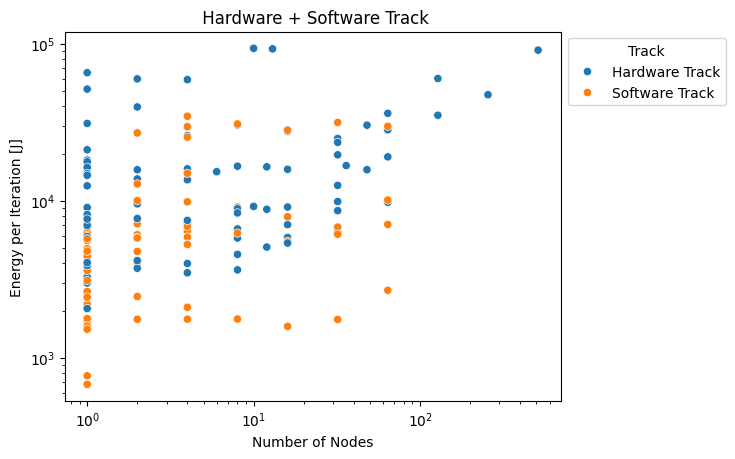

In [10]:
fig, ax = plt.subplots()
sb.scatterplot(dfs, x="Number of Nodes", y="Energy per Iteration [J]", hue="Track", ax=ax)
ax.set(xscale="log", yscale="log", title=" Hardware + Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
op.save_fig(fig, fig_folder, "FVOPSAllsubsEnergyPerIteration", doSaveFig)